# Relationships, Correlation, and Crosstabs

Explore relationships between variables and avoid overstating what they show.

> 🧭 This notebook focuses on practical data work. Examples are intentionally compact and do not cover machine learning.

## Learning goals
- Visualize relationships between numeric variables.
- Calculate Pearson and Spearman correlations.
- Use crosstabs to compare categorical variables.
- Explain why correlation does not establish causation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(7)
n = 160
hours = rng.uniform(0, 10, n)
score = 40 + 4.2 * hours + rng.normal(0, 8, n)
segment = rng.choice(["A", "B", "C"], n, p=[.4, .35, .25])
feedback = rng.choice(["Positive", "Neutral", "Negative"], n, p=[.55, .3, .15])
df = pd.DataFrame({"hours": hours, "score": score, "segment": segment, "feedback": feedback})
display(df.head())

,hours,score,segment,feedback
0,6.250955,79.486470,B,Positive
1,8.972138,72.313114,C,Negative
2,7.756857,64.146049,C,Positive
3,2.252072,52.157313,A,Positive
4,3.001663,63.865162,A,Positive


Spearman: 0.842


/mnt/data/data_science_data_work/6. Exploratory Data Analysis/16_relationships_correlations_and_crosstabs.ipynb:5: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "id": "6aa1f365",


,hours,score
hours,1.000000,0.826789
score,0.826789,1.000000


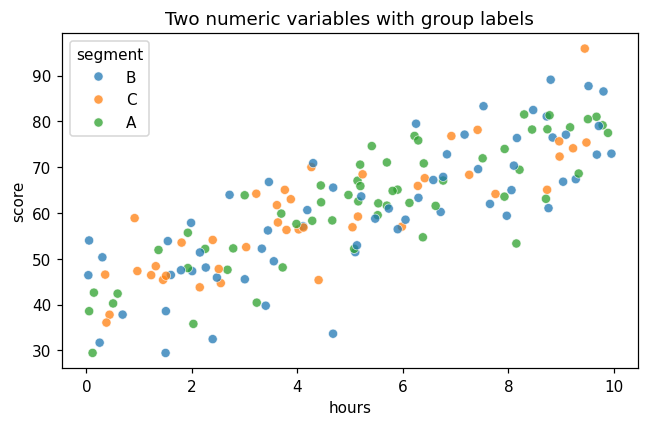

In [2]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.scatterplot(data=df, x="hours", y="score", hue="segment", alpha=.75, ax=ax)
ax.set_title("Two numeric variables with group labels")
plt.tight_layout()
plt.show()

corr = df[["hours", "score"]].corr(method="pearson")
display(corr)
print("Spearman:", round(df["hours"].corr(df["score"], method="spearman"), 3))

## Correlation caveats
- Pearson correlation measures linear association and is sensitive to outliers.
- Spearman correlation uses ranks and can detect monotonic relationships.
- A low correlation does not rule out a nonlinear relationship.
- A third variable, selection effects, or time can explain an observed association.

Pearson: -0.002
Spearman: -0.003


/mnt/data/data_science_data_work/6. Exploratory Data Analysis/16_relationships_correlations_and_crosstabs.ipynb:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "\n",


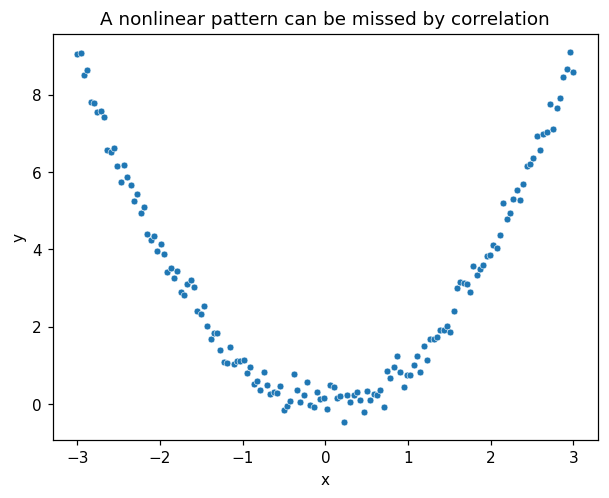

In [3]:
# An intentionally nonlinear relationship may have a weak Pearson correlation.
x = np.linspace(-3, 3, 150)
y = x**2 + rng.normal(0, .25, size=len(x))
nonlinear = pd.DataFrame({"x": x, "y": y})
print("Pearson:", round(nonlinear.x.corr(nonlinear.y, method="pearson"), 3))
print("Spearman:", round(nonlinear.x.corr(nonlinear.y, method="spearman"), 3))
sns.scatterplot(data=nonlinear, x="x", y="y", s=20)
plt.title("A nonlinear pattern can be missed by correlation")
plt.show()

## Crosstabs for categorical data
Counts and row-normalized percentages answer different questions. Use the denominator that matches your question and report it explicitly.

/mnt/data/data_science_data_work/6. Exploratory Data Analysis/16_relationships_correlations_and_crosstabs.ipynb:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "# Relationships, Correlation, and Crosstabs\n",


feedback,Negative,Neutral,Positive
segment,,,
A,4,16,37
B,9,23,30
C,8,10,23


feedback,Negative,Neutral,Positive
segment,,,
A,7.0,28.1,64.9
B,14.5,37.1,48.4
C,19.5,24.4,56.1


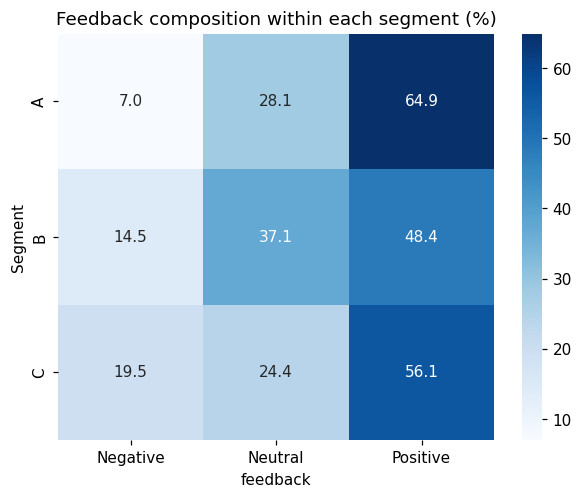

In [4]:
counts = pd.crosstab(df["segment"], df["feedback"])
row_percent = pd.crosstab(df["segment"], df["feedback"], normalize="index").mul(100).round(1)
display(counts)
display(row_percent)
sns.heatmap(row_percent, annot=True, fmt=".1f", cmap="Blues")
plt.title("Feedback composition within each segment (%)")
plt.ylabel("Segment")
plt.show()

## Practice
Create a crosstab of two categorical columns and compare Pearson and Spearman correlation for a numeric pair. Write one sentence that does not claim causality.

In [5]:
display(pd.crosstab(df["segment"], df["feedback"], normalize="index").round(2))
print("Pearson:", df["hours"].corr(df["score"], method="pearson"))
print("Spearman:", df["hours"].corr(df["score"], method="spearman"))

Pearson: 0.8267885146450304
Spearman: 0.8415797492089534


feedback,Negative,Neutral,Positive
segment,,,
A,0.07,0.28,0.65
B,0.15,0.37,0.48
C,0.20,0.24,0.56
